In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [3]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [4]:
missing_percent = (df.isnull().sum() / len(df)) * 100

print(missing_percent)

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [5]:
df.dtypes


PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [6]:
df.drop(columns=['Cabin'], inplace=True)


C:\Users\Mon Pc\AppData\Local\Temp\ipykernel_8700\2791896709.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Cabin'], inplace=True)


In [13]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='str')

In [14]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [15]:
df['Age'].isnull().sum()


np.int64(0)

In [17]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [18]:
df['Embarked'].isnull().sum()

np.int64(0)

In [19]:
df.isnull().sum()


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

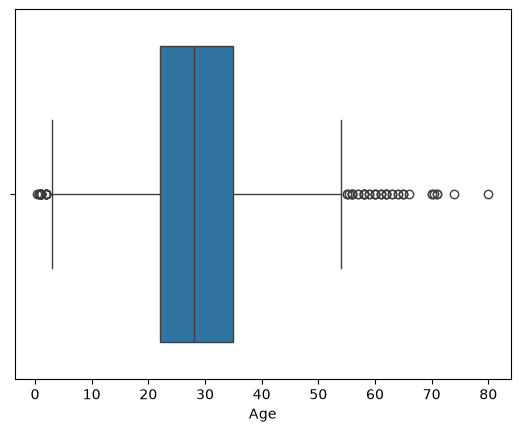

In [20]:
sns.boxplot(x=df['Age'])
plt.show()


In [24]:
mediane_age = df['Age'].median()

df.loc[(df['Age'] < borne_inf) | (df['Age'] > borne_sup), 'Age'] = mediane_age

In [25]:
df[(df['Age'] < borne_inf) | (df['Age'] > borne_sup)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked


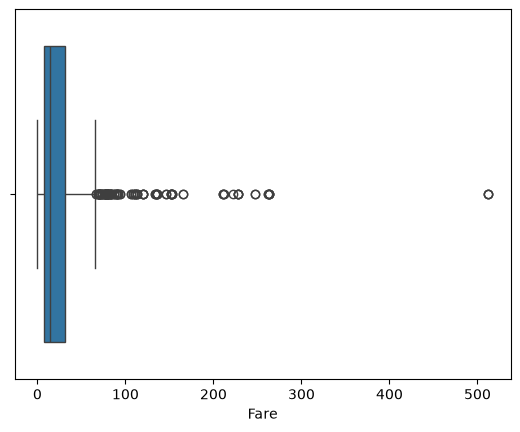

In [26]:
sns.boxplot(x=df['Fare'])
plt.show()

In [31]:
mediane_fare = df['Fare'].median()

df.loc[(df['Fare'] < borne_inf) | (df['Fare'] > borne_sup), 'Fare'] = mediane_fare

In [32]:
df[(df['Fare'] < borne_inf) | (df['Fare'] > borne_sup)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked


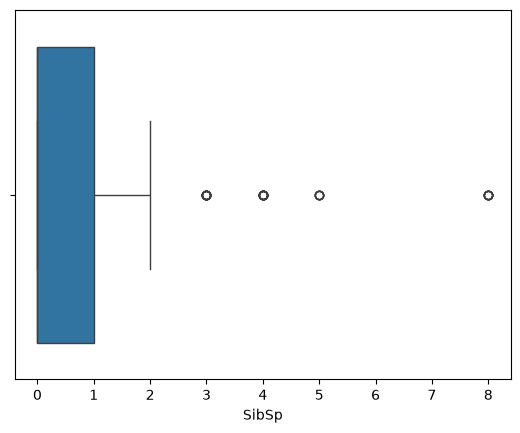

In [33]:
sns.boxplot(x=df['SibSp'])
plt.show()

In [37]:
mediane_sibsp = df['SibSp'].median()

df.loc[
    (df['SibSp'] < borne_inf) | (df['SibSp'] > borne_sup),
    'SibSp'
] = mediane_sibsp

In [38]:
df[(df['SibSp'] < borne_inf) | (df['SibSp'] > borne_sup)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked


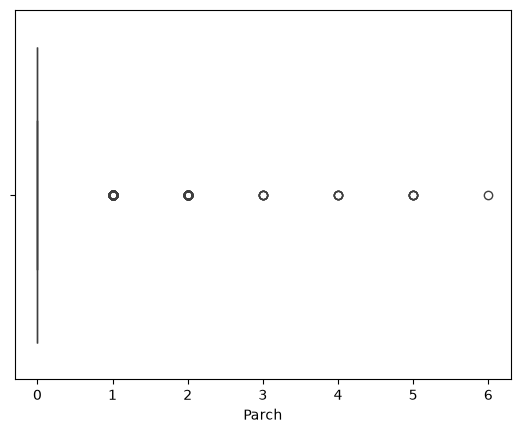

In [39]:
sns.boxplot(x=df['Parch'])
plt.show()

In [42]:
mediane_parch = df['Parch'].median()

df.loc[df['Parch'] > borne_sup, 'Parch'] = mediane_parch

In [43]:
df[df['Parch'] > borne_sup]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked


In [44]:
df.shape

(891, 11)

In [48]:
df = pd.get_dummies(df, columns=['Sex', 'Embarked'], dtype=int)


In [49]:
df.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,0,1,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,14.4542,1,0,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,1,0,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,1,0,0,0,1
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,0,1,0,0,1


In [50]:
from sklearn.preprocessing import MinMaxScaler

colonnes_num = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

df_minmax = df.copy()

scaler_minmax = MinMaxScaler()

df_minmax[colonnes_num] = scaler_minmax.fit_transform(df[colonnes_num])

df_minmax[colonnes_num].head()

,Pclass,Age,SibSp,Parch,Fare
0,1.0,0.372549,0.5,0.0,0.111538
1,0.0,0.686275,0.5,0.0,0.222372
2,1.0,0.450980,0.0,0.0,0.121923
3,0.0,0.627451,0.5,0.0,0.816923
4,1.0,0.627451,0.0,0.0,0.123846


In [51]:
from sklearn.preprocessing import StandardScaler

df_standard = df.copy()

scaler_standard = StandardScaler()

df_standard[colonnes_num] = scaler_standard.fit_transform(df[colonnes_num])

df_standard[colonnes_num].head()

,Pclass,Age,SibSp,Parch,Fare
0,0.827377,-0.661724,1.347605,0.0,-0.797554
1,-1.566107,0.972921,1.347605,0.0,-0.230556
2,0.827377,-0.253063,-0.570472,0.0,-0.744429
3,-1.566107,0.666425,1.347605,0.0,2.811012
4,0.827377,0.666425,-0.570472,0.0,-0.734591


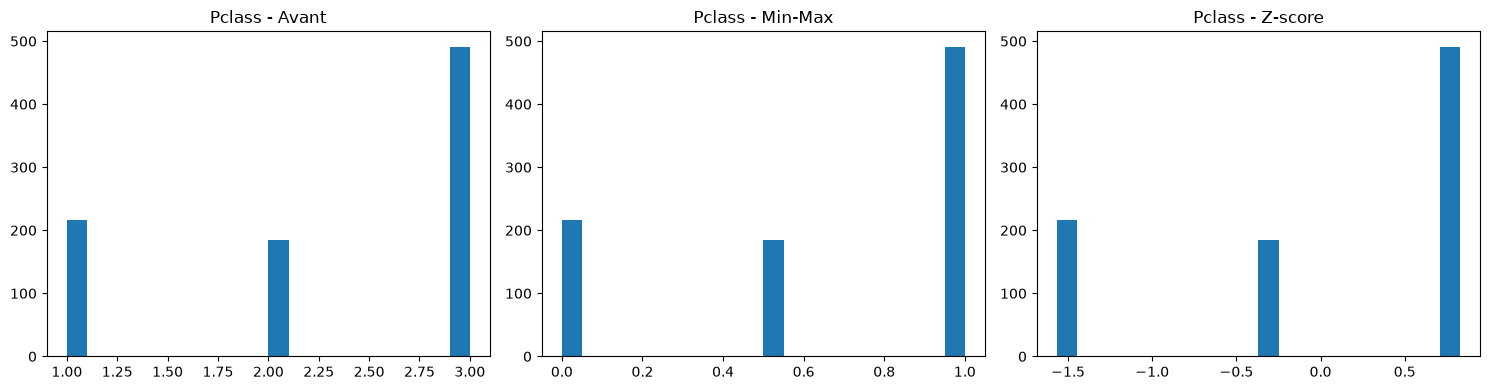

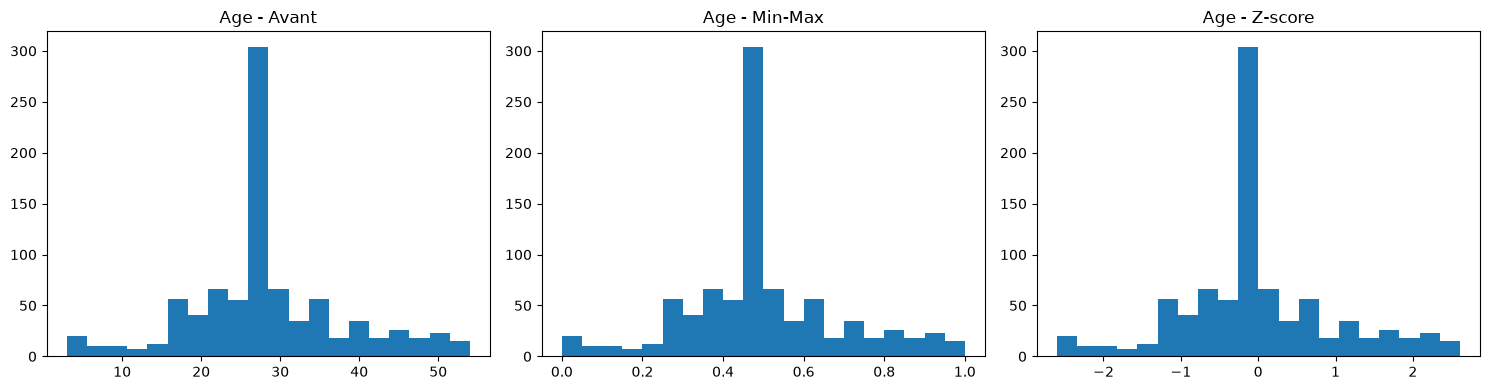

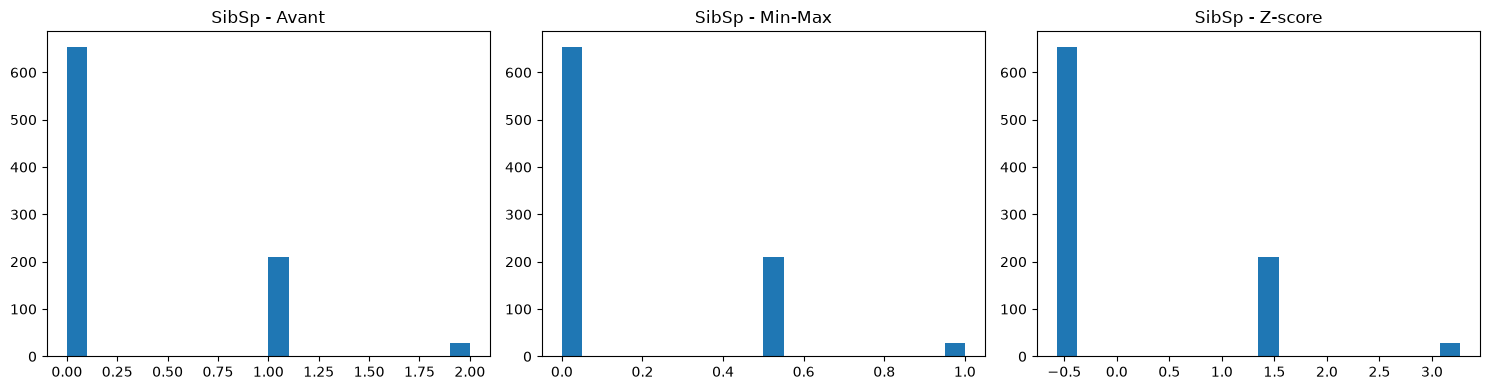

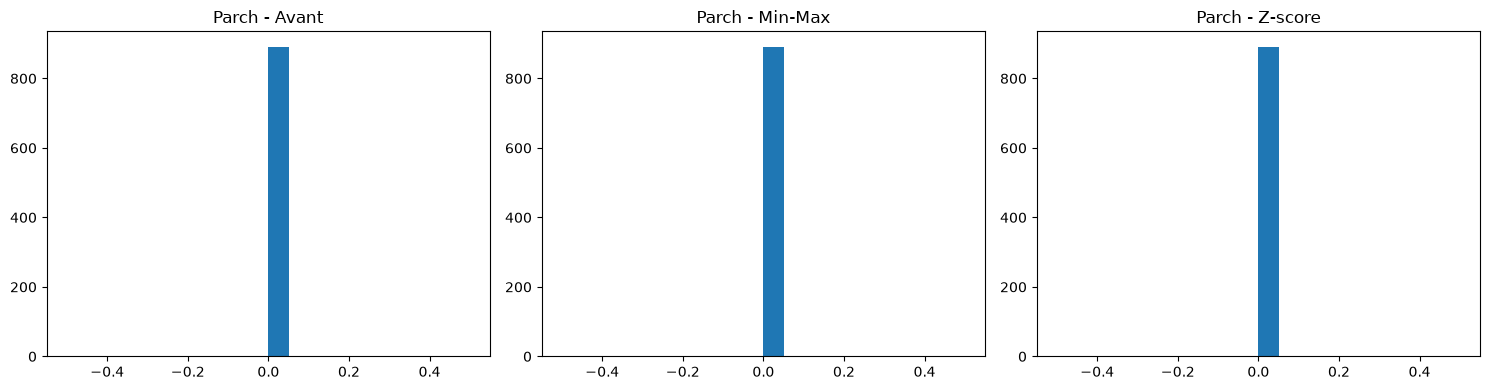

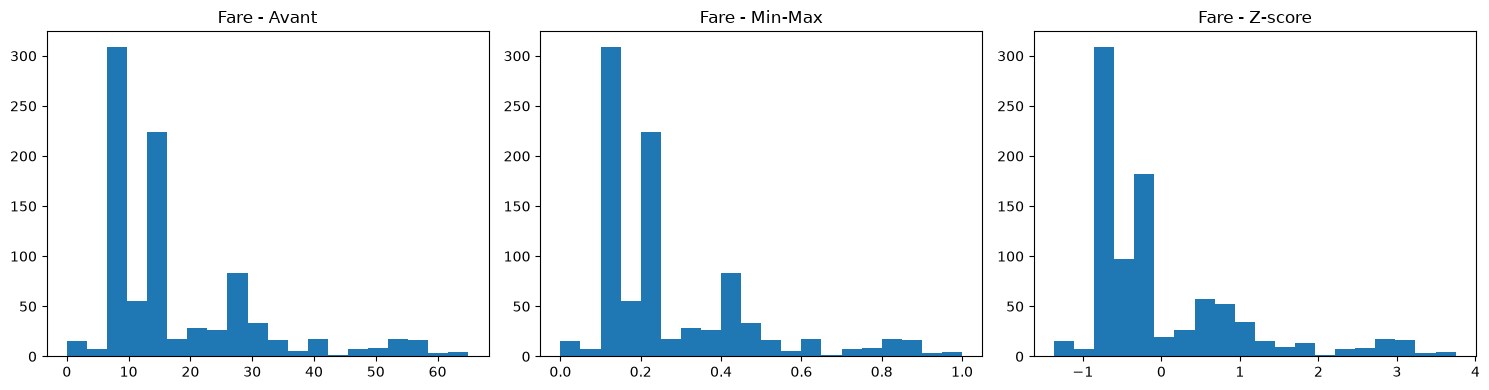

In [52]:
for col in colonnes_num:
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.hist(df[col], bins=20)
    plt.title(col + ' - Avant')

    plt.subplot(1, 3, 2)
    plt.hist(df_minmax[col], bins=20)
    plt.title(col + ' - Min-Max')

    plt.subplot(1, 3, 3)
    plt.hist(df_standard[col], bins=20)
    plt.title(col + ' - Z-score')

    plt.tight_layout()
    plt.show()

In [53]:
df['Survived'].value_counts()


Survived
0    549
1    342
Name: count, dtype: int64

In [54]:
from imblearn.under_sampling import RandomUnderSampler

X = df.drop(columns=['Survived', 'Name', 'Ticket', 'PassengerId'])
y = df['Survived']

rus = RandomUnderSampler(random_state=42)

X_under, y_under = rus.fit_resample(X, y)

y_under.value_counts()

Survived
0    342
1    342
Name: count, dtype: int64

In [55]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_smote, y_smote = smote.fit_resample(X, y)

y_smote.value_counts()

Survived
0    549
1    549
Name: count, dtype: int64